# Reproduction: Deep Learning for Portfolio Optimization (Zhang, Zohren & Roberts, 2020)

Paper: https://arxiv.org/abs/2005.13665

This notebook reproduces **Method A** (the paper's LSTM model) from the group project methodology:
a single LSTM reads the last 50 days of all 4 assets together and outputs long-only portfolio
weights, trained end-to-end to directly maximise the Sharpe ratio (no return-forecasting step).

**Pipeline:** load data &rarr; build 50-day windows &rarr; LSTM(64) + softmax &rarr; Sharpe loss
&rarr; walk-forward train/test (retrain every 2 years) &rarr; volatility scaling + transaction
costs at evaluation time &rarr; metrics &rarr; compare against the paper's Table 1.

**Assets:** VTI (US stocks), AGG (US bonds), DBC (commodities), ^VIX (volatility) &mdash; daily,
2006-02-07 to 2020-04-29, from `Dataset-Original.csv`.

> Preprocessing note: the paper does not fully specify how raw prices are scaled before being fed
> to the network. Here each window's prices are indexed to the most recent day in that window
> (so the last day = 1.0); this uses only information already known at decision time and keeps
> the network's inputs on a consistent scale. This is a documented implementation choice, not a
> detail taken from the paper.


In [1]:
# ---- Setup ----
import os, random, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)


Using device: cpu


## 1. Load the dataset

If you're running this in Colab and the CSV isn't already in the working directory, the cell
below will prompt you to upload `Dataset-Original.csv`.

In [2]:
# ---- Load data ----
FNAME = "Dataset-Original.csv"

if not os.path.exists(FNAME):
    try:
        from google.colab import files
        print(f"'{FNAME}' not found in the working directory — please upload it.")
        uploaded = files.upload()
        FNAME = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"'{FNAME}' not found, and this isn't Colab so I can't prompt an upload. "
            "Put the CSV in the working directory and re-run this cell."
        )

df = pd.read_csv(FNAME, parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
print(df.shape)
df.head()


'Dataset-Original.csv' not found in the working directory — please upload it.


Saving Dataset-Original.csv to Dataset-Original.csv
(3581, 25)


,Date,AGG_Adj Close,DBC_Adj Close,VTI_Adj Close,^VIX_Adj Close,AGG_Close,DBC_Close,VTI_Close,^VIX_Close,AGG_High,...,VTI_Low,^VIX_Low,AGG_Open,DBC_Open,VTI_Open,^VIX_Open,AGG_Volume,DBC_Volume,VTI_Volume,^VIX_Volume
0,2006-02-07,52.519066,18.630157,43.285564,13.59,100.139999,23.500000,62.549999,13.59,100.339996,...,62.500000,12.97,100.330002,24.049999,63.000000,13.20,122900,674400,570000,0
1,2006-02-08,52.492867,18.550882,43.596962,12.83,100.089996,23.400000,63.000000,12.83,100.239998,...,62.505001,12.76,100.190002,23.490000,62.619999,13.41,146800,335400,396400,0
2,2006-02-09,52.524323,18.725290,43.513927,13.12,100.150002,23.620001,62.880001,13.12,100.250000,...,62.820000,12.27,100.129997,23.559999,63.174999,12.56,144200,705900,213000,0
3,2006-02-10,52.414207,18.384396,43.603889,12.87,99.940002,23.190001,63.009998,12.87,100.230003,...,62.404999,12.69,100.139999,23.650000,62.830002,13.35,118100,276700,359000,0
4,2006-02-13,52.450890,18.099003,43.406651,13.35,100.010002,22.830000,62.724998,13.35,100.010002,...,62.544998,13.05,99.989998,23.190001,62.970001,13.34,109600,237600,334200,0


In [3]:
# ---- Select assets & check for gaps/nulls ----
ASSETS = ["VTI", "AGG", "DBC", "VIX"]           # fixed, consistent order used throughout
COLMAP = {"VTI": "VTI_Adj Close", "AGG": "AGG_Adj Close",
          "DBC": "DBC_Adj Close", "VIX": "^VIX_Adj Close"}

prices = df[[COLMAP[a] for a in ASSETS]].copy()
prices.columns = ASSETS
prices.index = df["Date"]

print("Date range:", prices.index.min().date(), "to", prices.index.max().date())
print("Missing values per asset:\n", prices.isnull().sum())
assert prices.isnull().sum().sum() == 0, "Unexpected missing prices — handle before continuing."


Date range: 2006-02-07 to 2020-04-29
Missing values per asset:
 VTI    0
AGG    0
DBC    0
VIX    0
dtype: int64


## 2. Compute returns and build 50-day windows

For each decision day *t*, the input window covers days *t-50 .. t-1* (prices indexed to the
window's last day, plus daily returns). The training target is the **true return realised on
day *t*** for every asset &mdash; this is what the predicted weights get multiplied against in
the Sharpe loss. Because the window stops at *t-1* and the target is day *t*, there is no
look-ahead.

In [4]:
# ---- Daily returns ----
returns = prices.pct_change().dropna()
prices_aligned = prices.loc[returns.index]     # drop the first row (no return available)
dates = returns.index.to_numpy()

price_arr = prices_aligned.values.astype(np.float64)   # (T, 4)
ret_arr = returns.values.astype(np.float64)             # (T, 4)
T = len(dates)
print("Usable days after return calc:", T)


Usable days after return calc: 3580


In [5]:
# ---- Build windowed samples ----
WINDOW = 50
N_ASSETS = len(ASSETS)

X_list, y_list, tgt_dates = [], [], []
for t in range(WINDOW, T):
    win_price = price_arr[t - WINDOW:t]          # (50, 4) — days t-50 .. t-1
    win_ret = ret_arr[t - WINDOW:t]               # (50, 4)
    norm_price = win_price / win_price[-1]        # index to the window's most recent day
    feat = np.concatenate([norm_price, win_ret], axis=1)   # (50, 8): price then return per asset
    X_list.append(feat)
    y_list.append(ret_arr[t])                     # true next-day (day t) returns — the target
    tgt_dates.append(dates[t])

X = np.stack(X_list).astype(np.float32)            # (N, 50, 8)
y = np.stack(y_list).astype(np.float32)             # (N, 4)
target_dates = pd.to_datetime(tgt_dates)

print("X:", X.shape, " y:", y.shape)
print("Target date range:", target_dates.min().date(), "to", target_dates.max().date())


X: (3530, 50, 8)  y: (3530, 4)
Target date range: 2006-04-21 to 2020-04-29


In [6]:
# ---- Volatility estimate for evaluation-time scaling (Eq. 6/7 in the methodology doc) ----
# sigma_{i,t-1}: 50-day exponentially-weighted std of DAILY returns, annualised (x sqrt(252))
# since vol_target below is an ANNUAL target (10%) — mixing an annual target with a daily sigma
# would massively over-leverage low-vol assets like bonds. Shifted by 1 day so it only uses
# information through day t-1 (the same cutoff as the price/return window above).
ANNUALISE = np.sqrt(252)
ewm_vol = (returns.ewm(span=WINDOW, min_periods=WINDOW).std() * ANNUALISE).shift(1)
ewm_vol = ewm_vol.loc[target_dates]
sigma_arr = ewm_vol.values.astype(np.float32)       # (N, 4), aligned row-for-row with X and y

print("Mean annualised volatility per asset over the full sample:")
print(pd.Series(np.nanmean(sigma_arr, axis=0), index=ASSETS).round(3))


Mean annualised volatility per asset over the full sample:
VTI    0.167
AGG    0.040
DBC    0.178
VIX    1.226
dtype: float32


## 3. Dataset, model and Sharpe loss

**Model (Method A):** a single-layer LSTM (64 units) reads the 50x8 window; its final hidden
state is passed through a dense layer to 4 raw scores, then softmax to long-only weights.

**Loss:** the Sharpe ratio of the mini-batch's portfolio returns, maximised via gradient ascent
(implemented as minimising the negative Sharpe). Sharpe is order-invariant across a batch (it
only depends on the batch's mean and standard deviation), so ordinary shuffled mini-batches of
size 64 are equivalent to the paper's batching.

In [7]:
# ---- PyTorch Dataset ----
class WindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X)
        self.y = torch.tensor(y)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, i):
        return self.X[i], self.y[i]


In [8]:
# ---- Model: LSTM -> Dense -> softmax ----
class LSTMSharpeNet(nn.Module):
    def __init__(self, n_features=8, hidden=64, n_assets=4):
        super().__init__()
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden,
                             num_layers=1, batch_first=True)
        self.fc = nn.Linear(hidden, n_assets)

    def forward(self, x):
        out, _ = self.lstm(x)          # out: (batch, 50, hidden)
        last = out[:, -1, :]           # final hidden state summarises the window
        raw = self.fc(last)            # (batch, n_assets) raw scores
        weights = torch.softmax(raw, dim=1)
        return weights


In [9]:
# ---- Sharpe loss ----
def sharpe_loss(weights, y_true, eps=1e-9):
    port_ret = (weights * y_true).sum(dim=1)        # realised portfolio return per sample
    mu = port_ret.mean()
    sigma = port_ret.std(unbiased=False)
    sharpe = mu / (sigma + eps)
    return -sharpe                                   # minimise negative Sharpe = maximise Sharpe


## 4. Walk-forward training

Following the paper: retrain every 2 years, using **all data available up to that point**, and
hold out the most recent 10% of the training samples (chronologically, not shuffled) as a
validation set. Training uses Adam, mini-batch 64, up to 100 epochs, with early stopping on
validation Sharpe (a practical addition — the paper fixes 100 epochs but doesn't rule this out;
set `PATIENCE` high or `EPOCHS=100` with no stopping if you want the strict reading).

In [10]:
# ---- Config ----
EPOCHS = 100
PATIENCE = 15
BATCH_SIZE = 64
LR = 1e-3
VAL_FRAC = 0.10

def chronological_val_split(Xtr, ytr, val_frac=VAL_FRAC):
    n = len(Xtr)
    n_val = max(1, int(n * val_frac))
    cut = n - n_val
    return (Xtr[:cut], ytr[:cut]), (Xtr[cut:], ytr[cut:])

def train_one_cycle(X_tr, y_tr, X_val, y_val, epochs=EPOCHS, patience=PATIENCE,
                     batch_size=BATCH_SIZE, lr=LR, device=DEVICE, verbose=False):
    model = LSTMSharpeNet().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(WindowDataset(X_tr, y_tr), batch_size=batch_size,
                         shuffle=True, drop_last=True)
    Xv = torch.tensor(X_val).to(device)
    yv = torch.tensor(y_val).to(device)

    best_val, best_state, wait = -1e9, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = sharpe_loss(model(xb), yb)
            loss.backward()
            opt.step()

        model.eval()
        with torch.no_grad():
            val_sharpe = -sharpe_loss(model(Xv), yv).item()
        if verbose:
            print(f"  epoch {epoch:3d}  val Sharpe = {val_sharpe:.4f}")

        if val_sharpe > best_val:
            best_val = val_sharpe
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    model.load_state_dict(best_state)
    return model, best_val


In [11]:
# ---- Walk-forward schedule: test 2011-01-01 to end of data, retrained every 2 years ----
TEST_START = pd.Timestamp("2011-01-01")
last_date = target_dates.max()

block_starts = pd.date_range(TEST_START, last_date, freq="2YS")
block_ranges = []
for i, bs in enumerate(block_starts):
    be = block_starts[i + 1] if i + 1 < len(block_starts) else last_date + pd.Timedelta(days=1)
    block_ranges.append((bs, be))

for bs, be in block_ranges:
    print(bs.date(), "to", (be - pd.Timedelta(days=1)).date())


2011-01-01 to 2012-12-31
2013-01-01 to 2014-12-31
2015-01-01 to 2016-12-31
2017-01-01 to 2018-12-31
2019-01-01 to 2020-04-29


In [12]:
# ---- Run the walk-forward loop ----
all_test_dates, all_test_weights, all_test_true_ret = [], [], []
cycle_log = []

for bstart, bend in block_ranges:
    train_mask = target_dates < bstart
    test_mask = (target_dates >= bstart) & (target_dates < bend)
    if test_mask.sum() == 0:
        continue

    Xtr_all, ytr_all = X[train_mask], y[train_mask]
    (Xtr, ytr), (Xval, yval) = chronological_val_split(Xtr_all, ytr_all)

    model, val_sh = train_one_cycle(Xtr, ytr, Xval, yval)
    cycle_log.append((bstart.date(), bend.date(), len(Xtr), len(Xval), int(test_mask.sum()), val_sh))
    print(f"Block {bstart.date()} - {(bend - pd.Timedelta(days=1)).date()}: "
          f"train={len(Xtr)} val={len(Xval)} test={int(test_mask.sum())} "
          f"val_Sharpe={val_sh:.3f}")

    Xte, yte = X[test_mask], y[test_mask]
    model.eval()
    with torch.no_grad():
        w_te = model(torch.tensor(Xte).to(DEVICE)).cpu().numpy()

    all_test_dates.append(target_dates[test_mask])
    all_test_weights.append(w_te)
    all_test_true_ret.append(yte)

test_dates = np.concatenate(all_test_dates)
test_weights = np.concatenate(all_test_weights)
test_true_ret = np.concatenate(all_test_true_ret)

print("\nTotal out-of-sample days:", len(test_dates))


Block 2011-01-01 - 2012-12-31: train=1066 val=118 test=502 val_Sharpe=0.167
Block 2013-01-01 - 2014-12-31: train=1518 val=168 test=504 val_Sharpe=0.157
Block 2015-01-01 - 2016-12-31: train=1971 val=219 test=504 val_Sharpe=0.247
Block 2017-01-01 - 2018-12-31: train=2425 val=269 test=502 val_Sharpe=0.172
Block 2019-01-01 - 2020-04-29: train=2877 val=319 test=334 val_Sharpe=0.270

Total out-of-sample days: 2346


## 5. Volatility scaling, transaction costs and evaluation metrics

At evaluation time only (never during training), positions are rescaled to a common 10%
volatility target and a cost is charged on every change in (scaled) position, following the
methodology document's Eq. 6/7:

- `u_{i,t-1} = (sigma_target / sigma_{i,t-1}) * w_{i,t-1}`
- `R_{p,t} = sum_i u_{i,t-1} * r_{i,t} - C * sum_i |u_{i,t-1} - u_{i,t-2}|`

`sigma_target` is an **annual** target (10%), so `sigma_{i,t-1}` must also be annualised
(daily EWM std x sqrt(252)) — otherwise a 10% annual target gets divided by a ~0.3% daily
number and positions get leveraged by 30-40x, which is wrong.

We report three settings, matching the paper's Table 1: no scaling (C = 0.01%), volatility
scaling at 10% (C = 0.01%), and volatility scaling at 10% with a higher cost (C = 0.1%).

In [13]:
# ---- Sanity check: sigma array lines up with the concatenated test arrays ----
test_mask_full = (target_dates >= TEST_START) & (target_dates <= last_date)
assert np.array_equal(target_dates[test_mask_full].values, test_dates), \
    "Date alignment mismatch between the walk-forward loop and sigma_arr."
sigma_test = sigma_arr[test_mask_full]


In [14]:
# ---- Apply volatility scaling + transaction costs ----
def compute_scaled_returns(weights, true_ret, sigma, vol_target=None, cost_rate=0.0001):
    if vol_target is None:
        u = weights.copy()
    else:
        scale = vol_target / sigma
        scale = np.nan_to_num(scale, nan=1.0, posinf=1.0, neginf=1.0)
        u = scale * weights

    gross = (u * true_ret).sum(axis=1)
    # turnover cost: |change in scaled position| summed over assets; no cost on the very first
    # day of the backtest (no prior position to compare against).
    turnover = np.abs(np.diff(u, axis=0, prepend=u[[0]])).sum(axis=1)
    cost = cost_rate * turnover
    return gross - cost

settings = {
    "No scaling, C=0.01%":      dict(vol_target=None, cost_rate=0.0001),
    "Vol scaling 10%, C=0.01%": dict(vol_target=0.10,  cost_rate=0.0001),
    "Vol scaling 10%, C=0.1%":  dict(vol_target=0.10,  cost_rate=0.0010),
}

returns_by_setting = {
    name: compute_scaled_returns(test_weights, test_true_ret, sigma_test, **cfg)
    for name, cfg in settings.items()
}


In [15]:
# ---- Metrics ----
def compute_metrics(daily_returns, ann_factor=252):
    r = np.asarray(daily_returns, dtype=np.float64)
    mean = r.mean() * ann_factor
    std = r.std(ddof=0) * np.sqrt(ann_factor)
    sharpe = mean / std if std > 0 else np.nan

    downside = r[r < 0]
    dd = downside.std(ddof=0) * np.sqrt(ann_factor) if len(downside) > 0 else np.nan
    sortino = mean / dd if dd and dd > 0 else np.nan

    cum = np.cumprod(1 + r)
    peak = np.maximum.accumulate(cum)
    mdd = np.max((peak - cum) / peak)

    pct_pos = (r > 0).mean()
    avg_p = r[r > 0].mean() if (r > 0).any() else np.nan
    avg_l = r[r < 0].mean() if (r < 0).any() else np.nan
    pl_ratio = avg_p / abs(avg_l) if avg_l and avg_l != 0 else np.nan

    return {"E(R)": mean, "Std(R)": std, "Sharpe": sharpe, "DD(R)": dd,
            "Sortino": sortino, "MDD": mdd, "% of + Ret": pct_pos, "Ave.P/Ave.L": pl_ratio}

results = pd.DataFrame({name: compute_metrics(r) for name, r in returns_by_setting.items()}).T
results = results.round(3)
results


,E(R),Std(R),Sharpe,DD(R),Sortino,MDD,% of + Ret,Ave.P/Ave.L
"No scaling, C=0.01%",0.110,0.047,2.328,0.038,2.895,0.092,0.569,1.207
"Vol scaling 10%, C=0.01%",0.101,0.071,1.426,0.055,1.845,0.111,0.563,0.994
"Vol scaling 10%, C=0.1%",0.084,0.071,1.191,0.055,1.537,0.116,0.555,0.983


In [16]:
# ---- Reproduction check against the paper's Table 1 (LSTM / DLS row) ----
paper_table1 = pd.DataFrame({
    "No scaling, C=0.01%":      {"Sharpe": 1.858, "Sortino": 3.135, "E(R)": 0.313, "MDD": 0.102},
    "Vol scaling 10%, C=0.01%": {"Sharpe": 1.962, "Sortino": 3.322, "E(R)": 0.206, "MDD": 0.123},
    "Vol scaling 10%, C=0.1%":  {"Sharpe": 1.403, "Sortino": 2.327, "E(R)": 0.148, "MDD": 0.125},
}).T

compare = results[["Sharpe", "Sortino", "E(R)", "MDD"]].join(
    paper_table1, lsuffix="_ours", rsuffix="_paper"
)
compare = compare[["Sharpe_ours", "Sharpe_paper", "Sortino_ours", "Sortino_paper",
                    "E(R)_ours", "E(R)_paper", "MDD_ours", "MDD_paper"]]
compare


,Sharpe_ours,Sharpe_paper,Sortino_ours,Sortino_paper,E(R)_ours,E(R)_paper,MDD_ours,MDD_paper
"No scaling, C=0.01%",2.328,1.858,2.895,3.135,0.110,0.313,0.092,0.102
"Vol scaling 10%, C=0.01%",1.426,1.962,1.845,3.322,0.101,0.206,0.111,0.123
"Vol scaling 10%, C=0.1%",1.191,1.403,1.537,2.327,0.084,0.148,0.116,0.125


## 6. Cumulative returns

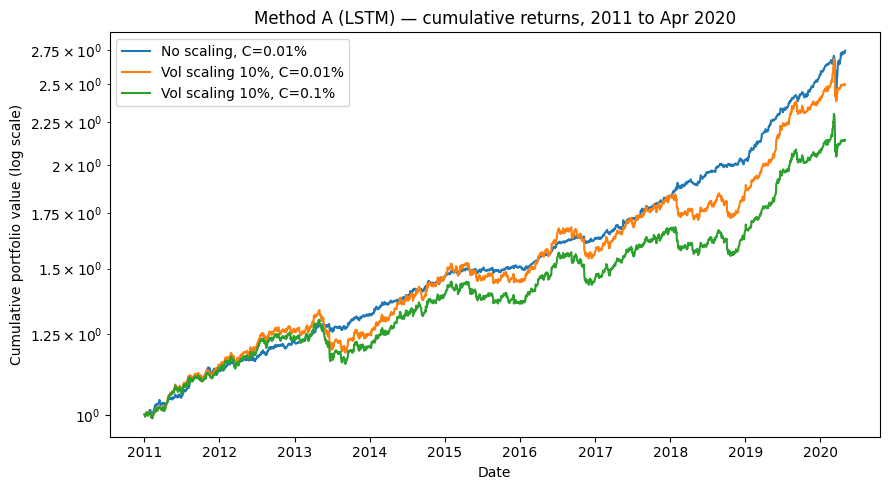

In [17]:
# ---- Plot cumulative returns (log scale) for the three settings ----
plt.figure(figsize=(9, 5))
for name, r in returns_by_setting.items():
    cum = np.cumprod(1 + r)
    plt.plot(test_dates, cum, label=name)
plt.yscale("log")
plt.xlabel("Date")
plt.ylabel("Cumulative portfolio value (log scale)")
plt.title("Method A (LSTM) — cumulative returns, 2011 to Apr 2020")
plt.legend()
plt.tight_layout()
plt.show()


## 7. Save outputs for later use (Methods B, C, D)

Saves the out-of-sample weights, true returns and dates so the same test period and target
arrays can be reused when building the Attention and EIIE variants, without re-deriving the
windowing logic.

In [18]:
# ---- Save test-period outputs ----
np.savez("method_A_lstm_outputs.npz",
         test_dates=test_dates.astype(str),
         test_weights=test_weights,
         test_true_ret=test_true_ret,
         sigma_test=sigma_test)

results.to_csv("method_A_lstm_metrics.csv")
print("Saved method_A_lstm_outputs.npz and method_A_lstm_metrics.csv")


Saved method_A_lstm_outputs.npz and method_A_lstm_metrics.csv
